


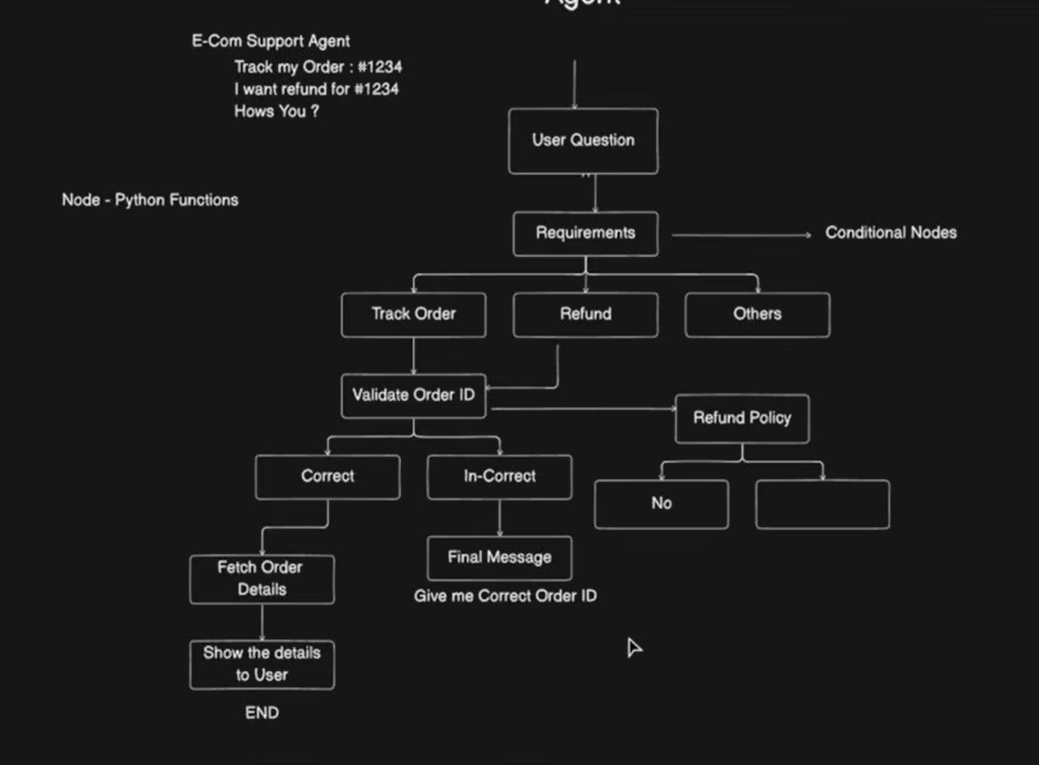



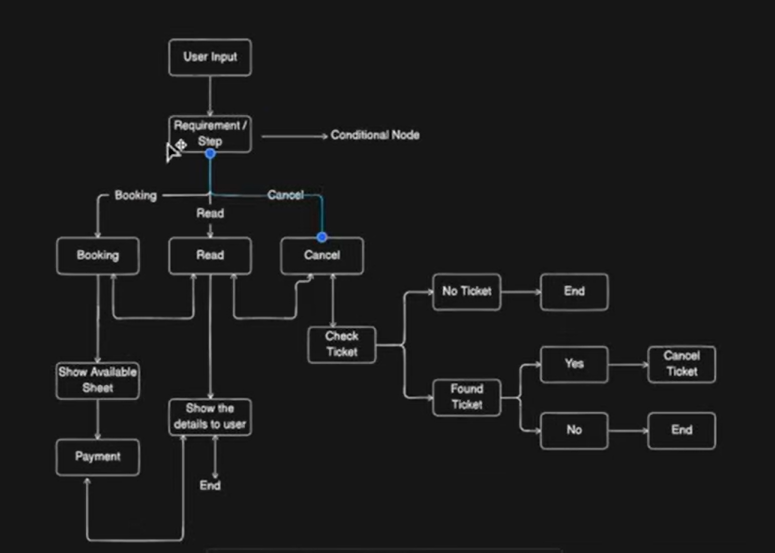

In [ ]:
from pydantic import BaseModel
# we will save the data of each node into a "state"
from langgraph.graph import StateGraph, START, END

In [69]:
class GreetState(BaseModel):
    messagee:str = ""

In [70]:
# State to save the data
graph_state = StateGraph(GreetState)
graph_state

In [71]:
# nodes - python functions

# Node=1
def Greet(state:GreetState):
    state.messagee = f"Hi Langgraph: {state.messagee}"
    return state

# Node=2
def upper_case(state:GreetState):
    state.messagee = state.messagee.upper()
    return state

In [72]:
# adding the node=1
graph_state.add_node("greet", Greet)

In [73]:
# adding the node=2
graph_state.add_node("Upper_case", upper_case)

In [74]:
# building the edgees
# START -> Greet -> Upper_case -> END
graph_state.add_edge(START, "greet")
graph_state.add_edge("greet", "Upper_case")
graph_state.add_edge("Upper_case", END)

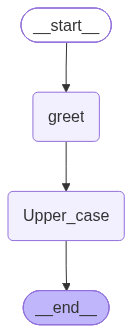

In [75]:
# compile the graph
final_graph = graph_state.compile()
final_graph

In [76]:
# Now alongwith message we are getting uppercase response
res = final_graph.invoke({"message": "I lives in Rouen"})
res

{'messagee': 'HI LANGGRAPH: '}